# Perbandingan Model Naive Bayes untuk Klasifikasi Domain Punycode

Notebook ini membandingkan lima varian utama Naive Bayes pada scikit-learn:

- Gaussian Naive Bayes
- Multinomial Naive Bayes
- Complement Naive Bayes
- Bernoulli Naive Bayes
- Categorical Naive Bayes

GaussianNB memakai fitur kontinu, CategoricalNB memakai fitur diskret, dan tiga model lainnya memakai character n-gram. Eksperimen hanya menggunakan hostname/domain.

## Tujuan Perbandingan

GaussianNB pada notebook sebelumnya menggunakan ringkasan numerik domain dan memperoleh recall phishing yang terbatas. Character n-gram mempertahankan pola lokal seperti `xn--`, potongan nama domain, kombinasi angka-huruf, serta susunan karakter yang sulit diringkas menjadi beberapa statistik.

Semua model memakai data dan pembagian grup yang sama agar hasil dapat dibandingkan secara adil.

## 1. Persiapan Lingkungan

In [1]:
from pathlib import Path
from urllib.parse import urlsplit
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB, CategoricalNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
)

SEED = 42
N_REGULAR = 65_000
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Bins whose width are too small.*")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 5.5), "axes.titleweight": "bold"})
print("Lingkungan siap | Seed:", SEED)

Lingkungan siap | Seed: 42


## 2. Membentuk Dataset yang Sama

Komposisi yang digunakan adalah 65.000 Tranco, 65.000 PhishTank, 5.000 Punycode legitimate-source, dan 5.000 Punycode phishing-source. Konflik URL identik dengan label berbeda disaring dari kandidat Tranco.

In [2]:
BASE_DIR = Path.cwd()
required = ["tranco_6WNKX.csv", "verified_online.csv",
            "legitimate_punycode_5000.csv", "phishing_punycode_5000.csv"]
assert all((BASE_DIR / f).exists() for f in required), "Ada file dataset yang tidak ditemukan."

legit_puny_raw = pd.read_csv(BASE_DIR / required[2]).head(5_000)
phish_puny_raw = pd.read_csv(BASE_DIR / required[3]).head(5_000)
legit_puny = legit_puny_raw[["url", "label", "source_url"]].rename(
    columns={"source_url": "source_key"}).assign(data_type="synthetic", source_dataset="Punycode")
phish_puny = phish_puny_raw[["url", "label", "source_url"]].rename(
    columns={"source_url": "source_key"}).assign(data_type="synthetic", source_dataset="Punycode")

phishtank = pd.read_csv(BASE_DIR / required[1]).drop_duplicates("url").head(N_REGULAR)
phish_real = pd.DataFrame({
    "url": phishtank["url"].astype(str).str.strip(), "label": "phishing",
    "source_key": phishtank["url"].astype(str).str.strip(),
    "data_type": "real", "source_dataset": "PhishTank",
})

tranco = pd.read_csv(BASE_DIR / required[0], header=None, names=["rank", "domain"],
                     nrows=70_000).drop_duplicates("domain")
tranco = tranco[~("https://" + tranco["domain"].astype(str).str.strip()).isin(set(phish_real["url"]))]
tranco = tranco.head(N_REGULAR)
legit_real = pd.DataFrame({
    "url": "https://" + tranco["domain"].astype(str).str.strip(), "label": "legitimate",
    "source_key": tranco["domain"].astype(str).str.strip(),
    "data_type": "real", "source_dataset": "Tranco",
})

df = pd.concat([legit_real, phish_real, legit_puny, phish_puny], ignore_index=True)
assert len(df) == 140_000 and df["url"].nunique() == 140_000
display(pd.crosstab([df["source_dataset"], df["data_type"]], df["label"], margins=True))
print(f"Total: {len(df):,} | Duplikat: {df['url'].duplicated().sum()}")

,label,legitimate,phishing,All
source_dataset,data_type,,,
PhishTank,real,0,65000,65000
Punycode,synthetic,5000,5000,10000
Tranco,real,65000,0,65000
All,,70000,70000,140000


Total: 140,000 | Duplikat: 0


**Ringkasan output:** dataset berisi 140.000 URL unik dan kelas seimbang, masing-masing 70.000 legitimate dan phishing. Komposisi yang identik dengan eksperimen GaussianNB membuat perbandingan model tetap adil.

## 3. Normalisasi dan Ekstraksi Domain

Hostname dikonversi ke lowercase, trailing dot dan prefiks `www.` dihapus. Model hanya menerima string domain hasil normalisasi.

In [3]:
def normalized_domain(url):
    parsed = urlsplit(url if "://" in url else "https://" + url)
    host = (parsed.hostname or "").lower().rstrip(".")
    return host[4:] if host.startswith("www.") else host

df["domain"] = df["url"].map(normalized_domain)
df["contains_punycode"] = df["domain"].str.contains("xn--").astype(int)
assert (df["domain"] != "").all()

domain_audit = pd.Series({
    "domain_kosong": (df["domain"] == "").sum(),
    "domain_unik": df["domain"].nunique(),
    "domain_dengan_xn--": df["contains_punycode"].sum(),
})
display(domain_audit.to_frame("jumlah"))
display(df[["url", "domain", "label", "data_type"]].head(8))

,jumlah
domain_kosong,0
domain_unik,106412
domain_dengan_xn--,10127


,url,domain,label,data_type
0,https://google.com,google.com,legitimate,real
1,https://gtld-servers.net,gtld-servers.net,legitimate,real
2,https://cloudflare.com,cloudflare.com,legitimate,real
3,https://gstatic.com,gstatic.com,legitimate,real
4,https://facebook.com,facebook.com,legitimate,real
5,https://microsoft.com,microsoft.com,legitimate,real
6,https://googleapis.com,googleapis.com,legitimate,real
7,https://youtube.com,youtube.com,legitimate,real


**Ringkasan output:** semua URL berhasil diekstrak menjadi domain. Jumlah domain unik dapat lebih kecil dari jumlah URL karena PhishTank dapat memuat path berbeda pada hostname yang sama. Kondisi ini ditangani melalui group-aware split berdasarkan sumber URL.

## 4. Membagi Dataset 80:20

URL asli dan transformasi Punycode yang berhubungan ditempatkan pada partisi sama. Pembagian dilakukan per kelas agar proporsi legitimate dan phishing tetap seimbang.

In [4]:
y = df["label"].map({"legitimate": 0, "phishing": 1})
train_idx, test_idx = [], []
for cls in [0, 1]:
    idx = df.index[y == cls].to_numpy()
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
    local_train, local_test = next(splitter.split(idx, groups=df.loc[idx, "source_key"]))
    train_idx.extend(idx[local_train]); test_idx.extend(idx[local_test])

train_idx, test_idx = np.array(train_idx), np.array(test_idx)
domain_train, domain_test = df.loc[train_idx, "domain"], df.loc[test_idx, "domain"]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
assert set(df.loc[train_idx, "source_key"]).isdisjoint(set(df.loc[test_idx, "source_key"]))

split_table = pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()})
split_table.index = split_table.index.map({0: "legitimate", 1: "phishing"})
display(split_table)
print(f"Train: {len(train_idx):,} | Test: {len(test_idx):,} | Kebocoran grup: 0")

,train,test
label,,
legitimate,56009,13991
phishing,56033,13967


Train: 112,042 | Test: 27,958 | Kebocoran grup: 0


**Ringkasan output:** sekitar 80% data digunakan untuk pelatihan dan 20% untuk pengujian. Tidak terdapat pasangan sumber yang melintasi train dan test sehingga risiko kebocoran transformasi berkurang.

## 5. Representasi Fitur

N-gram 2–5 karakter menangkap potongan lokal domain. Vectorizer hanya belajar vocabulary dari data train. Batas 80.000 fitur menjaga kebutuhan memori tetap terkendali.

In [5]:
def entropy(text):
    probabilities = pd.Series(list(text)).value_counts(normalize=True)
    return float(-(probabilities * np.log2(probabilities)).sum())

def numeric_domain_features(series):
    result = pd.DataFrame(index=series.index)
    result["length"] = series.str.len()
    result["label_count"] = series.str.count(r"\.") + 1
    result["hyphen_count"] = series.str.count("-")
    result["digit_count"] = series.str.count(r"\d")
    result["digit_ratio"] = result["digit_count"] / result["length"].clip(lower=1)
    result["xn_count"] = series.str.count("xn--")
    result["punycode_ratio"] = series.str.findall(r"xn--[^.]+").map(
        lambda labels: sum(map(len, labels))) / result["length"].clip(lower=1)
    result["max_label_length"] = series.str.split(".").map(lambda x: max(map(len, x)))
    result["tld_length"] = series.str.rsplit(".", n=1).str[-1].str.len()
    result["entropy"] = series.map(entropy)
    return result

numeric = numeric_domain_features(df["domain"])
N_train, N_test = numeric.loc[train_idx], numeric.loc[test_idx]

vectorizer = TfidfVectorizer(
    analyzer="char", ngram_range=(2, 5), min_df=2,
    max_features=80_000, sublinear_tf=True, lowercase=False,
)
X_train = vectorizer.fit_transform(domain_train)
X_test = vectorizer.transform(domain_test)

print("Bentuk train:", X_train.shape)
print("Bentuk test :", X_test.shape)
print("Non-zero TF-IDF train:", f"{X_train.nnz:,}")
print("Jumlah fitur numerik:", N_train.shape[1])
display(pd.Series(vectorizer.get_feature_names_out()).sample(20, random_state=SEED).to_frame("contoh_ngram"))

Bentuk train: (112042, 80000)
Bentuk test : (27958, 80000)
Non-zero TF-IDF train: 5,431,314
Jumlah fitur numerik: 10


,contoh_ngram
47044,ltura
44295,ktopl
74783,v-ap
70975,to-m
46645,loq
8215,2u
65509,sa.e
62715,rienc
39859,igk
58834,penwe


**Ringkasan output:** setiap domain telah berubah menjadi vektor sparse dengan maksimal 80.000 fitur. Contoh n-gram menunjukkan bahwa model menerima potongan karakter, bukan label atau nama sumber dataset.

## 6. Pelatihan dan Pemilihan Parameter

Setiap model diuji pada beberapa nilai `alpha` menggunakan GroupKFold. F1 phishing menjadi kriteria pemilihan karena menyeimbangkan precision dan recall.

In [6]:
configs = {
    "GaussianNB": (Pipeline([("scale", StandardScaler()), ("model", GaussianNB())]),
                   N_train, {"model__var_smoothing": [1e-9, 1e-7, 1e-6]}, "numerik kontinu"),
    "CategoricalNB": (Pipeline([
        ("bins", KBinsDiscretizer(n_bins=10, encode="ordinal", strategy="quantile")),
        ("model", CategoricalNB()),
    ]), N_train, {"model__alpha": [0.01, 0.1, 1.0]}, "numerik diskret"),
    "MultinomialNB": (MultinomialNB(), X_train, {"alpha": [0.01, 0.1, 1.0]}, "TF-IDF n-gram"),
    "ComplementNB": (ComplementNB(), X_train, {"alpha": [0.01, 0.1, 1.0]}, "TF-IDF n-gram"),
    "BernoulliNB": (BernoulliNB(binarize=0.0), X_train, {"alpha": [0.01, 0.1, 1.0]}, "n-gram biner"),
}
cv = GroupKFold(n_splits=3)
train_groups = df.loc[train_idx, "source_key"]

best_models, tuning_rows = {}, []
for name, (estimator, train_matrix, grid, representation) in configs.items():
    search = GridSearchCV(estimator, grid, scoring="f1", cv=cv, n_jobs=1)
    search.fit(train_matrix, y_train, groups=train_groups)
    best_models[name] = (search.best_estimator_, representation)
    tuning_rows.append({
        "model": name, "representasi": representation,
        "parameter_terbaik": str(search.best_params_), "cv_f1": search.best_score_,
    })

tuning = pd.DataFrame(tuning_rows).sort_values("cv_f1", ascending=False)
display(tuning.style.format({"cv_f1": "{:.4f}"}))

,model,representasi,parameter_terbaik,cv_f1
4,BernoulliNB,n-gram biner,{'alpha': 0.01},0.9343
3,ComplementNB,TF-IDF n-gram,{'alpha': 0.01},0.9276
2,MultinomialNB,TF-IDF n-gram,{'alpha': 0.01},0.9276
1,CategoricalNB,numerik diskret,{'model__alpha': 0.01},0.8117
0,GaussianNB,numerik kontinu,{'model__var_smoothing': 1e-09},0.6971


**Ringkasan output:** BernoulliNB memperoleh F1 cross-validation tertinggi, yaitu **0,9343**, sedangkan MultinomialNB dan ComplementNB memperoleh **0,9276**. Ketiga model memilih `alpha=0,01`. Model final dipilih dari cross-validation data train, bukan dari test set.

## 7. Prediksi dan Perbandingan Metrik

In [7]:
def metric_row(name, truth, pred, prob, subset="Keseluruhan"):
    return {
        "model": name, "subset": subset, "n": len(truth),
        "accuracy": accuracy_score(truth, pred),
        "precision": precision_score(truth, pred, zero_division=0),
        "recall": recall_score(truth, pred, zero_division=0),
        "f1": f1_score(truth, pred, zero_division=0),
        "roc_auc": roc_auc_score(truth, prob),
        "pr_auc": average_precision_score(truth, prob),
    }

prediction_store, rows = {}, []
test_types = df.loc[test_idx, "data_type"].to_numpy()
for name, (model, representation) in best_models.items():
    test_matrix = N_test if representation in {"numerik kontinu", "numerik diskret"} else X_test
    pred = model.predict(test_matrix)
    prob = model.predict_proba(test_matrix)[:, 1]
    prediction_store[name] = (pred, prob)
    rows.append(metric_row(name, y_test, pred, prob))
    for kind, title in [("real", "Data nyata"), ("synthetic", "Data sintetis")]:
        mask = test_types == kind
        rows.append(metric_row(name, y_test.to_numpy()[mask], pred[mask], prob[mask], title))

metrics = pd.DataFrame(rows)
overall = metrics[metrics["subset"] == "Keseluruhan"].sort_values("f1", ascending=False)
display(overall.style.format({c: "{:.4f}" for c in overall.columns[3:]}))
display(metrics.pivot(index="model", columns="subset", values="f1").style.format("{:.4f}"))

winner = tuning.iloc[0]["model"]
winner_pred, winner_prob = prediction_store[winner]
print("Model terbaik berdasarkan F1 test:", winner)

,model,subset,n,accuracy,precision,recall,f1,roc_auc,pr_auc
12,BernoulliNB,Keseluruhan,27958,0.9353,0.9800,0.8886,0.9321,0.9702,0.9762
9,ComplementNB,Keseluruhan,27958,0.9301,0.9612,0.8963,0.9276,0.9687,0.9769
6,MultinomialNB,Keseluruhan,27958,0.9301,0.9612,0.8963,0.9276,0.9687,0.9769
3,CategoricalNB,Keseluruhan,27958,0.8241,0.8633,0.7697,0.8138,0.8918,0.9040
0,GaussianNB,Keseluruhan,27958,0.7529,0.8915,0.5754,0.6994,0.8466,0.8576


subset,Data nyata,Data sintetis,Keseluruhan
model,,,
BernoulliNB,0.9325,0.9269,0.9321
CategoricalNB,0.8176,0.7763,0.8138
ComplementNB,0.9288,0.9112,0.9276
GaussianNB,0.6831,0.8600,0.6994
MultinomialNB,0.9288,0.9112,0.9276


Model terbaik berdasarkan F1 test: BernoulliNB


**Ringkasan output:** BernoulliNB memberikan F1 terbaik **93,21%**, diikuti MultinomialNB dan ComplementNB **92,76%**, CategoricalNB **81,38%**, serta GaussianNB **69,94%**. F1 BernoulliNB juga relatif konsisten pada data nyata (**93,25%**) dan sintetis (**92,69%**).

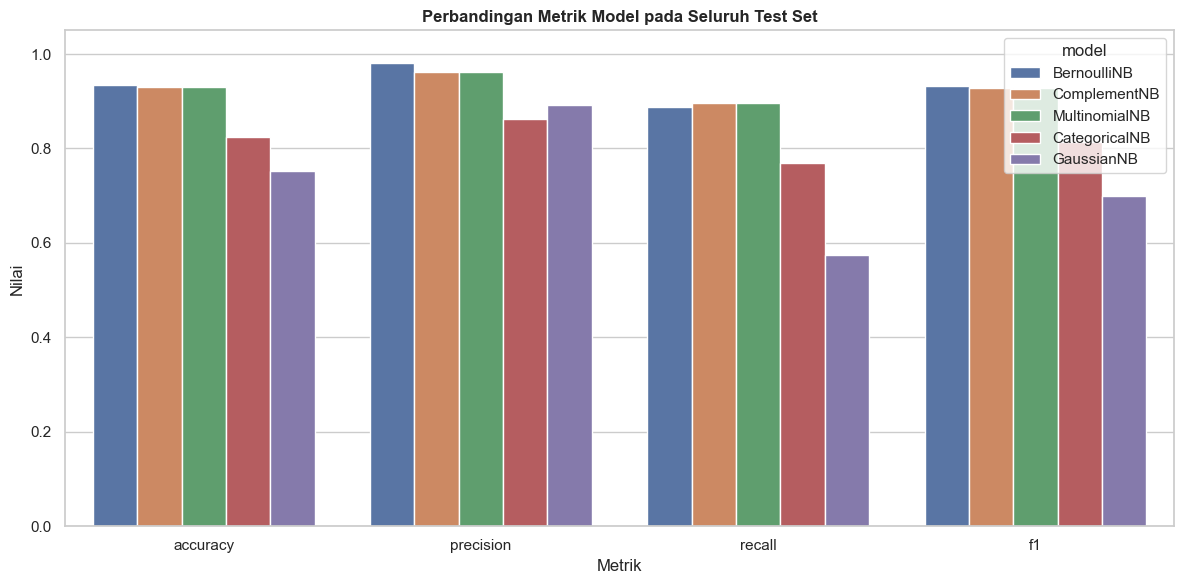

In [8]:
metric_plot = overall.melt(id_vars=["model", "subset", "n"],
                           value_vars=["accuracy", "precision", "recall", "f1"])
plt.figure(figsize=(12, 6))
sns.barplot(data=metric_plot, x="variable", y="value", hue="model")
plt.title("Perbandingan Metrik Model pada Seluruh Test Set")
plt.xlabel("Metrik"); plt.ylabel("Nilai"); plt.ylim(0, 1.05)
plt.tight_layout(); plt.show()

## 8. Evaluasi Model Terbaik

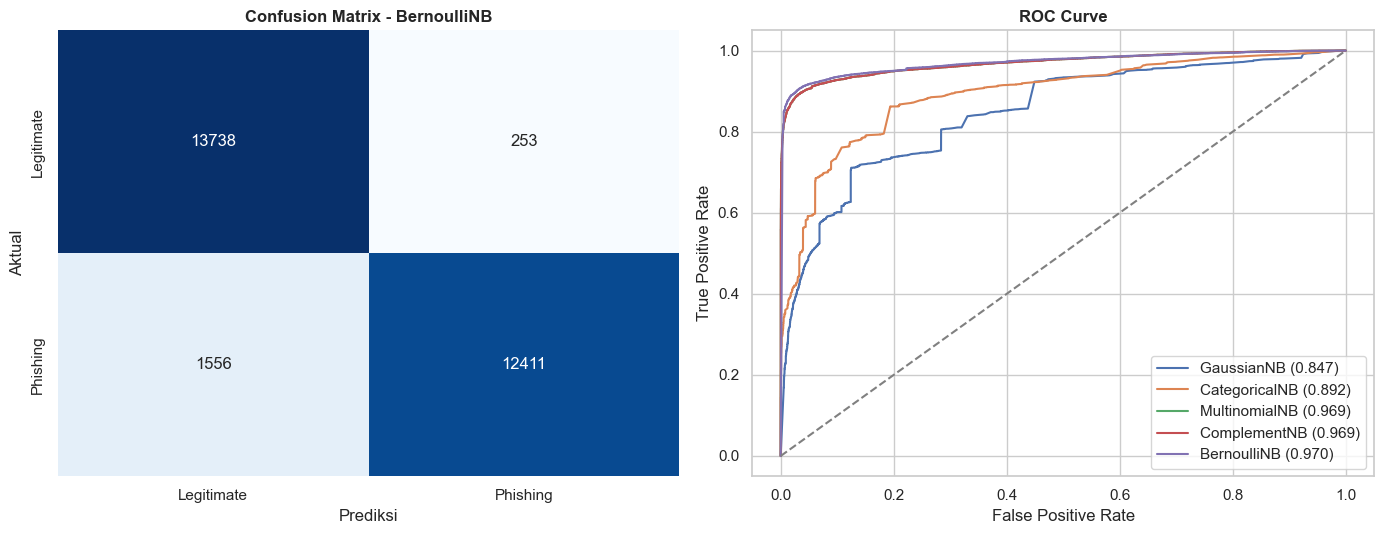

              precision    recall  f1-score   support

  legitimate     0.8983    0.9819    0.9382     13991
    phishing     0.9800    0.8886    0.9321     13967

    accuracy                         0.9353     27958
   macro avg     0.9391    0.9353    0.9351     27958
weighted avg     0.9391    0.9353    0.9352     27958

TN=13,738 | FP=253 | FN=1,556 | TP=12,411


In [9]:
cm = confusion_matrix(y_test, winner_pred)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Legitimate", "Phishing"], yticklabels=["Legitimate", "Phishing"], ax=axes[0])
axes[0].set(title=f"Confusion Matrix - {winner}", xlabel="Prediksi", ylabel="Aktual")

for name, (_, prob) in prediction_store.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[1].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, prob):.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set(title="ROC Curve", xlabel="False Positive Rate", ylabel="True Positive Rate")
axes[1].legend()
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(classification_report(y_test, winner_pred, target_names=["legitimate", "phishing"], digits=4))
print(f"TN={tn:,} | FP={fp:,} | FN={fn:,} | TP={tp:,}")

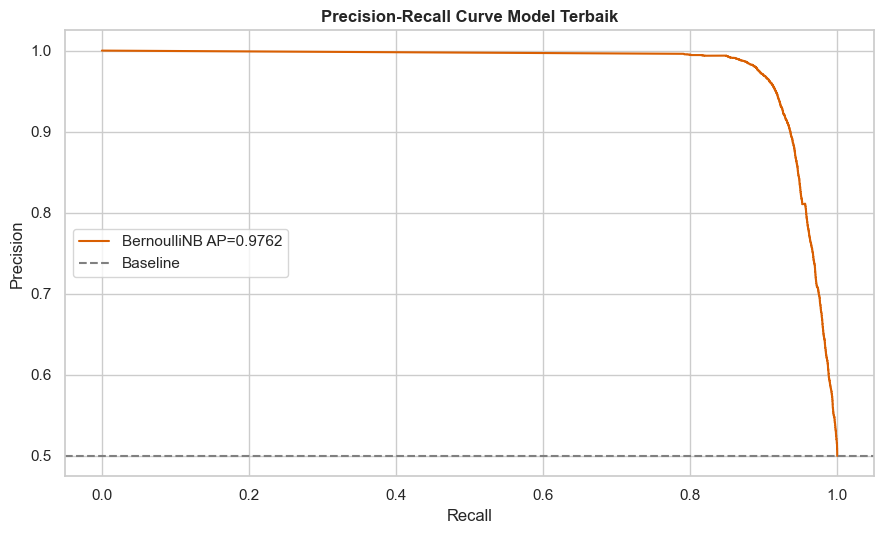

In [10]:
pr_precision, pr_recall, thresholds = precision_recall_curve(y_test, winner_prob)
plt.figure(figsize=(9, 5.5))
plt.plot(pr_recall, pr_precision, color="#d95f02",
         label=f"{winner} AP={average_precision_score(y_test, winner_prob):.4f}")
plt.axhline(y_test.mean(), linestyle="--", color="gray", label="Baseline")
plt.title("Precision-Recall Curve Model Terbaik")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend(); plt.tight_layout(); plt.show()